# Project 2
## Goals
Use scheduled flight information to predict:

1. Binary classification:
- 0: flight delays under 15 minutes
- 1: flight delays of 15 minutes or more

2. Multiclass classification:
- 0: flight delays under 15 minutes
- 1: flight delays of 15 minutes or more and under 60 minutes
- 2: flight delays of 60 minutes or more

In [3]:
%pip install numpy pandas matplotlib scikit-learn seaborn jupyter

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.0.2-cp39-cp39-macosx_14_0_arm64.whl (5.3 MB)
  Using cached pandas-2.3.3-cp39-cp39-macosx_11_0_arm64.whl (10.8 MB)
  Using cached matplotlib-3.9.4-cp39-cp39-macosx_11_0_arm64.whl (7.8 MB)
  Using cached scikit_learn-1.6.1-cp39-cp39-macosx_12_0_arm64.whl (11.1 MB)
     |████████████████████████████████| 294 kB 5.5 MB/s eta 0:00:01
  Using cached jupyter-1.1.1-py2.py3-none-any.whl (2.7 kB)
     |████████████████████████████████| 506 kB 37.9 MB/s eta 0:00:01
  Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
  Using cached importlib_resources-6.5.2-py3-none-any.whl (37 kB)
  Using cached pillow-11.3.0-cp39-cp39-macosx_11_0_arm64.whl (4.7 MB)
  Using cached kiwisolver-1.4.7-cp39-cp39-macosx_11_0_arm64.whl (64 kB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached contourpy-1.3.0-cp39-cp39-macosx_11_0_arm64.whl (249 kB)
  Using cached fonttools-4.60.2-cp39-cp39-macos

In [6]:
from pathlib import Path
from time import perf_counter
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

In [7]:
SEED = 10
MAX_SAMPLES = 20000
CV_FOLDS = 5
OUTPUT_DIR = Path("project2_output")
OUTPUT_DIR.mkdir(exist_ok=True)

In [8]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles in current directory:")
print(list(Path.cwd().iterdir()))

Current working directory:
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2

Files in current directory:
[PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/.DS_Store'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/model_fitting.ipynb'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/README.md'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/.gitignore'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/preprocessing.py'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/req.txt'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/.ipynb_checkpoints'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/.git'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/data')]


In [9]:
for file in Path.cwd().rglob("*.csv"):
    print(file)

/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_results_multiclass_svm.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/flights_binary_validation.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/flights_multiclass.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/model_fitting_results.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_results_multiclass_decision_tree.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/flights_binary.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/flights_binary_train.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_results_binary_svm.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/flights_multiclass_validation.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-pr

In [10]:
categorical_features = [
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
]

numeric_features = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "SCHEDULED_DEPARTURE_HOUR",
    "SCHEDULED_DEPARTURE_MINUTE",
    "SCHEDULED_ARRIVAL_HOUR",
    "SCHEDULED_ARRIVAL_MINUTE",
    "SCHEDULED_TIME",
    "DISTANCE",
]

source_columns = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "SCHEDULED_DEPARTURE",
    "SCHEDULED_ARRIVAL",
    "SCHEDULED_TIME",
    "DISTANCE",
    "ARRIVAL_DELAY",
    "CANCELLED",
    "DIVERTED",
]

def process_HHMM_time(data):
    values = pd.to_numeric(data, errors="coerce")
    valid = values.notna() & values.mod(1).eq(0) & ((values.between(0, 2359) & values.mod(100).lt(60)) | values.eq(2400))
    values = values.where(valid).replace(2400, 0)
    return values.floordiv(100), values.mod(100)

processed_path = Path("data/preprocessed_flights.csv")
raw_path = Path("data/flights.csv")

data_path = processed_path if processed_path.exists() else raw_path

if not data_path.exists():
    raise FileNotFoundError(
        "File not found."
    )

df = pd.read_csv(
    data_path,
    usecols=lambda column: column in source_columns,
    dtype={column: "string" for column in categorical_features},
    low_memory=False,
)

loaded_rows = len(df)

for column in set(df.columns) - set(categorical_features):
    df[column] = pd.to_numeric(df[column], errors="coerce")

if "CANCELLED" in df.columns:
    df = df.loc[df["CANCELLED"].eq(0)].copy()

df = df.loc[
    df["DIVERTED"].eq(0)
    & df["ARRIVAL_DELAY"].notna()
    & np.isfinite(df["ARRIVAL_DELAY"])
].copy()

eligible_rows = len(df)

if MAX_SAMPLES is not None and len(df) > MAX_SAMPLES:
    df = df.sample(n=MAX_SAMPLES, random_state=SEED)

df = df.reset_index(drop=True)

# Normalize categorical missing values
for column in categorical_features:
    values = df[column].astype("string").str.strip()
    df[column] = values.replace("", pd.NA).astype(object)
    df.loc[pd.isna(df[column]), column] = np.nan

if len(df) < 200:
    raise ValueError("The project requires at least 200 samples per problem.")

df["SCHEDULED_DEPARTURE_HOUR"], df["SCHEDULED_DEPARTURE_MINUTE"] = process_HHMM_time(df["SCHEDULED_DEPARTURE"])
df["SCHEDULED_ARRIVAL_HOUR"], df["SCHEDULED_ARRIVAL_MINUTE"] = process_HHMM_time(df["SCHEDULED_ARRIVAL"])

print("Source:", data_path)
print(f"Loaded rows: {loaded_rows:,}")
print(f"Eligible rows: {eligible_rows:,}")
print(f"Selected rows: {len(df):,}")

display(df.head())

Source: data/flights.csv
Loaded rows: 5,819,079
Eligible rows: 5,714,008
Selected rows: 20,000


,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,DIVERTED,CANCELLED,SCHEDULED_DEPARTURE_HOUR,SCHEDULED_DEPARTURE_MINUTE,SCHEDULED_ARRIVAL_HOUR,SCHEDULED_ARRIVAL_MINUTE
0,12,28,1,WN,DEN,JAX,1825,185.0,1447,2330,58.0,0,0,18,25,23,30
1,3,19,4,MQ,IND,JFK,1245,124.0,665,1449,5.0,0,0,12,45,14,49
2,10,31,6,EV,10397,10685,2109,104.0,533,2153,-8.0,0,0,21,9,21,53
3,8,4,2,UA,SNA,DEN,1542,138.0,846,1900,-10.0,0,0,15,42,19,0
4,3,29,7,UA,DEN,SAN,2207,143.0,853,2330,-12.0,0,0,22,7,23,30


# Predictors:
- Date of flight (Month, day, and day of week)
- scheduled duration
- scheduled distance
- scheduled departure hour and minute
- scheduled arrival hour and minute
- airline
- origin airport
- destination airport

# Excluded predictors:
- Actual departure time
- Actual arrival time
- Departure delay
- Taxi times
- elapsed time
- delay-cause
These variables are removed from the data frame to prevent outcome leakage.

# response variable: 
- Arrival delay

In [11]:
feature_cols = categorical_features + numeric_features
X = df[feature_cols].copy()

X[numeric_features] = X[numeric_features].replace([np.inf, -np.inf], np.nan).astype(float)

targets = {
    "binary": df["ARRIVAL_DELAY"].ge(15).astype(int),
    "multiclass": pd.Series(np.select([
        df["ARRIVAL_DELAY"].lt(15),
        df["ARRIVAL_DELAY"].lt(60),
    ], [0, 1], default=2),
    index=df.index),
}

class_names = {
    "binary": ["on_time", "delayed"],
    "multiclass": ["on_time", "minor_delay", "major_delay"],
}

for classificationtype in targets:
    targets[classificationtype] = targets[classificationtype].rename(f"{classificationtype}_response")

display(X.isna().mean().to_frame("missing_fraction").sort_values("missing_fraction", ascending=False))

,missing_fraction
AIRLINE,0.0
ORIGIN_AIRPORT,0.0
DESTINATION_AIRPORT,0.0
MONTH,0.0
DAY,0.0
DAY_OF_WEEK,0.0
SCHEDULED_DEPARTURE_HOUR,0.0
SCHEDULED_DEPARTURE_MINUTE,0.0
SCHEDULED_ARRIVAL_HOUR,0.0
SCHEDULED_ARRIVAL_MINUTE,0.0


We will use a stratified 90/10 training/testing split on all of our models.

In [12]:

from sklearn.model_selection import train_test_split

splits = {}

for classificationtype, y in targets.items():
    if y.value_counts().min() < 10:
        raise ValueError(f"Not enough samples for {classificationtype} classification.")

    training, validation = train_test_split(
        np.arange(len(X)),
        test_size=0.10,
        stratify=y,
        random_state=SEED,
    )

    X_train = X.iloc[training].copy()
    y_train = y.iloc[training].copy()
    X_validation = X.iloc[validation].copy()
    y_validation = y.iloc[validation].copy()

    if y_train.value_counts().min() < CV_FOLDS:
        raise ValueError(f"Not enough training samples for {classificationtype} classification.")

    splits[classificationtype] = (X_train, y_train, X_validation, y_validation)

    # all data for task
    pd.concat([X, y], axis=1).to_csv(
        OUTPUT_DIR / f"flights_{classificationtype}.csv",
        index=False,
    )

    # training and validation data for task
    pd.concat([X_train, y_train], axis=1).to_csv(
        OUTPUT_DIR / f"flights_{classificationtype}_train.csv",
        index=False,
    )

    pd.concat([X_validation, y_validation], axis=1).to_csv(
        OUTPUT_DIR / f"flights_{classificationtype}_validation.csv",
        index=False,
    )

    print(f"{classificationtype}: {len(X_train):,} training samples, {len(X_validation):,} validation samples")


binary: 18,000 training samples, 2,000 validation samples
multiclass: 18,000 training samples, 2,000 validation samples


In [13]:
# explore data (visualization and stuff like that)

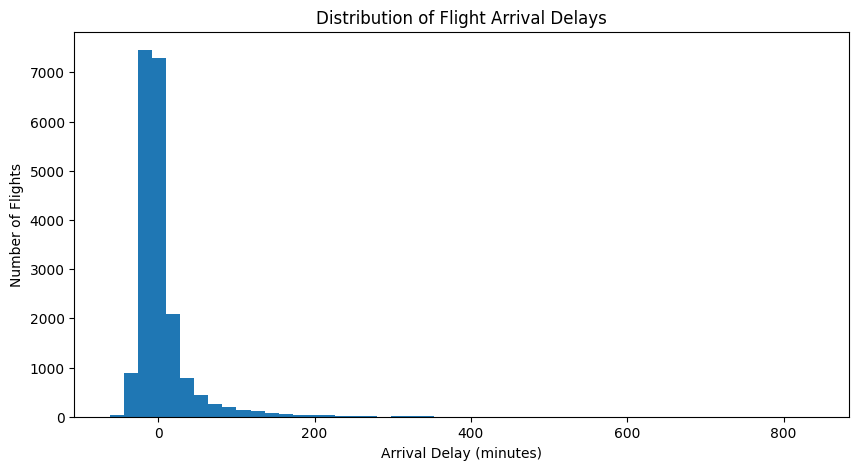

In [18]:
# distribution of arrival delays
plt.figure(figsize=(10, 5))

plt.hist(df["ARRIVAL_DELAY"], bins=50)

plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.title("Distribution of Flight Arrival Delays")

plt.show()

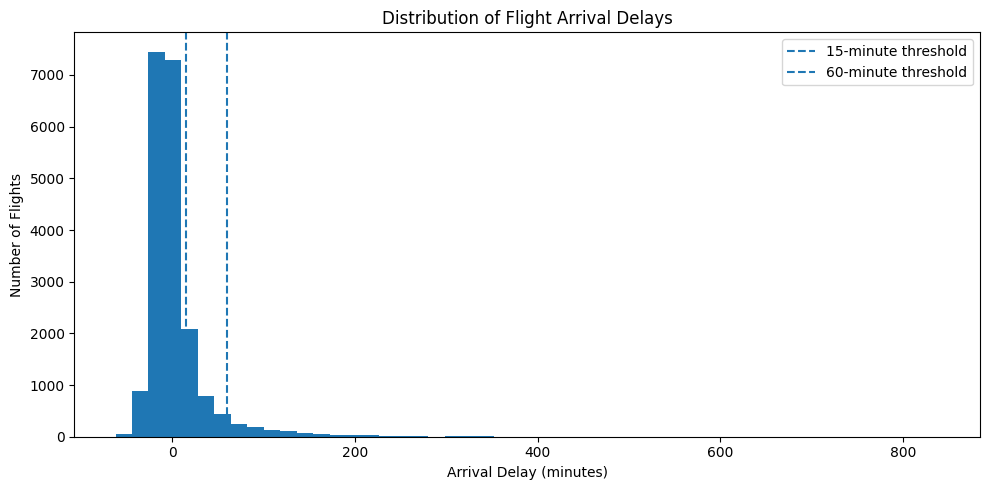

In [27]:
# distribution of arrival delays with classification thresholds
plt.figure(figsize=(10, 5))

plt.hist(df["ARRIVAL_DELAY"], bins=50)

plt.axvline(15, linestyle="--", label="15-minute threshold")
plt.axvline(60, linestyle="--", label="60-minute threshold")

plt.title("Distribution of Flight Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.legend()
plt.tight_layout()
plt.show()

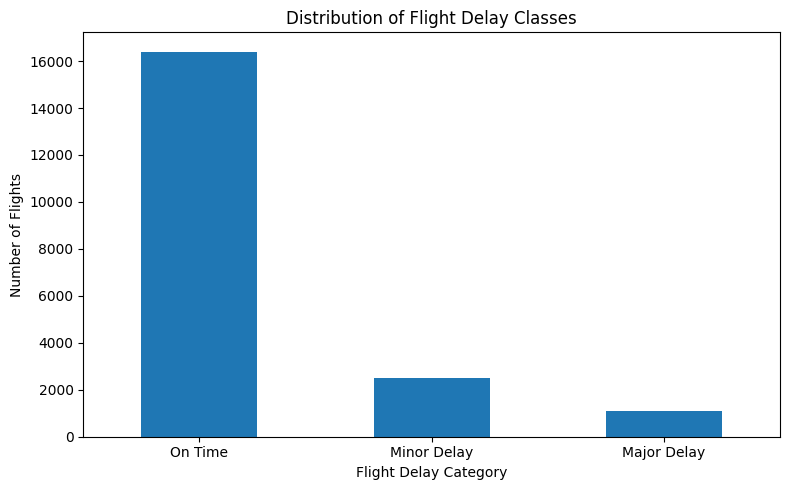

In [28]:
# target class distribution
plt.figure(figsize=(8, 5))

targets["multiclass"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xticks(
    [0, 1, 2],
    ["On Time", "Minor Delay", "Major Delay"],
    rotation=0
)

plt.title("Distribution of Flight Delay Classes")
plt.xlabel("Flight Delay Category")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

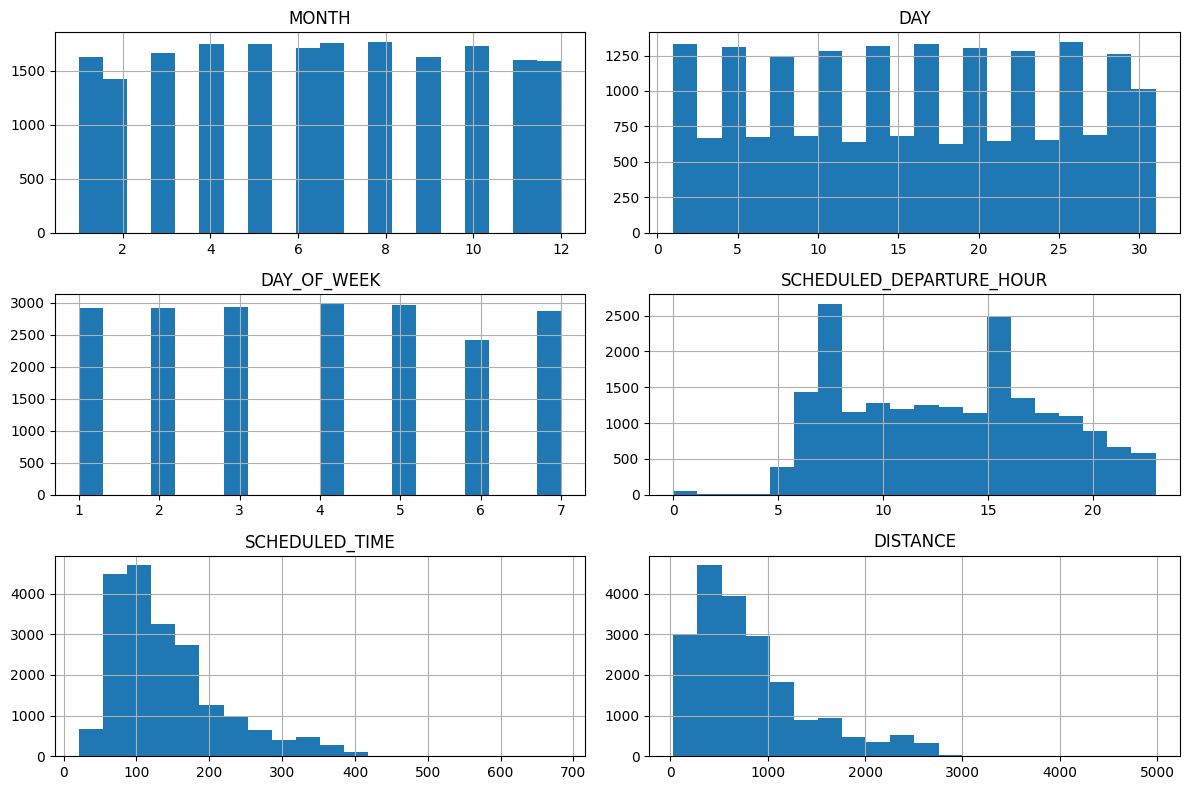

In [29]:
# distribution of numerical features
numeric_features = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "SCHEDULED_DEPARTURE_HOUR",
    "SCHEDULED_TIME",
    "DISTANCE"
]

df[numeric_features].hist(
    figsize=(12, 8),
    bins=20
)

plt.tight_layout()
plt.show()

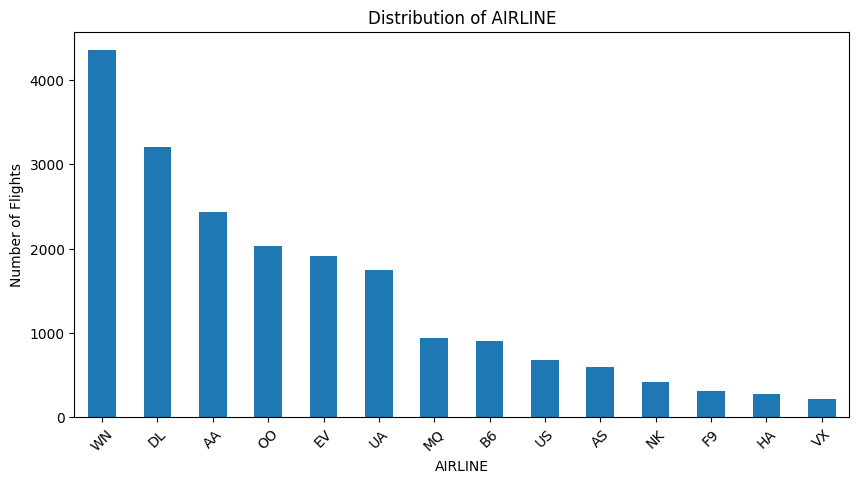

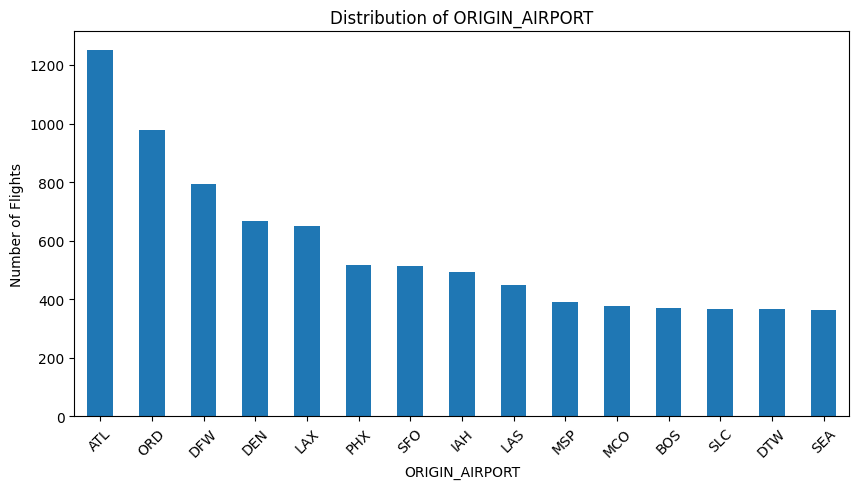

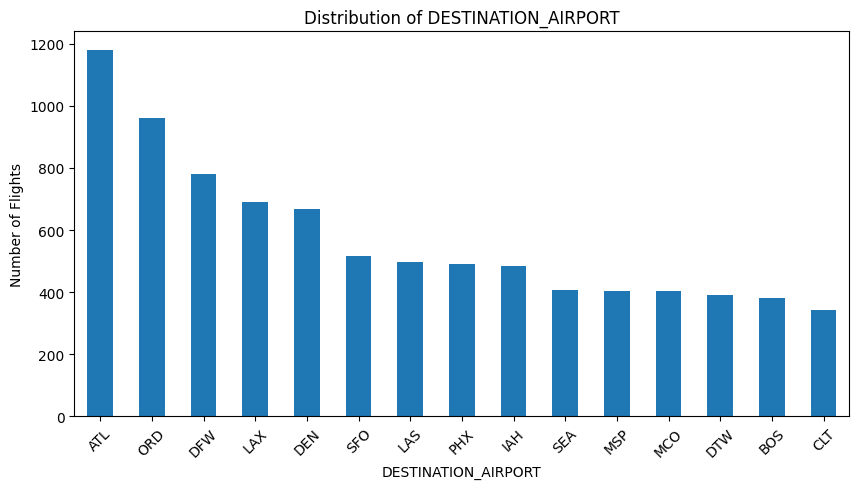

In [21]:
# distribution of categorical predictors
for column in categorical_features:
    plt.figure(figsize=(10, 5))

    df[column].value_counts().head(15).plot(
        kind="bar"
    )

    plt.title(f"Distribution of {column}")
    plt.ylabel("Number of Flights")
    plt.xticks(rotation=45)

    plt.show()

In [22]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

model_specs = {
    "decision_tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"model__max_depth": [3, 5, 10, 15, 20]}
    ),
    "svm": (
        SVC(random_state=SEED),
        {"model__kernel": ["linear", "poly", "rbf"]}
    ),
    "knn": (
        KNeighborsClassifier(n_jobs=-1),
        {
            "model__n_neighbors": [3, 5, 7, 9, 11],
            "model__weights": ["uniform", "distance"]
        }
    ),
    "random_forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {
            "model__max_depth": [5, 10, 15, 20, 25],
            "model__class_weight": [None, "balanced"]
        }
    )
}

models = list(model_specs)
for model in models:
    model_estimator, hyperparameters = model_specs[model]
    print(f"{model}: {model_estimator} with hyperparameters {hyperparameters}")

decision_tree: DecisionTreeClassifier(random_state=10) with hyperparameters {'model__max_depth': [3, 5, 10, 15, 20]}
svm: SVC(random_state=10) with hyperparameters {'model__kernel': ['linear', 'poly', 'rbf']}
knn: KNeighborsClassifier(n_jobs=-1) with hyperparameters {'model__n_neighbors': [3, 5, 7, 9, 11], 'model__weights': ['uniform', 'distance']}
random_forest: RandomForestClassifier(n_jobs=-1, random_state=10) with hyperparameters {'model__max_depth': [5, 10, 15, 20, 25], 'model__class_weight': [None, 'balanced']}


In [23]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

def make_pipeline(model_estimator):
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features),
        ]
    )

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", clone(model_estimator)),
    ])

    return pipeline

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.7950
Validation balanced accuracy: 0.5194
Validation macro F1:          0.5094
Final training runtime:       0.1383 seconds
Prediction runtime:           0.0033 seconds


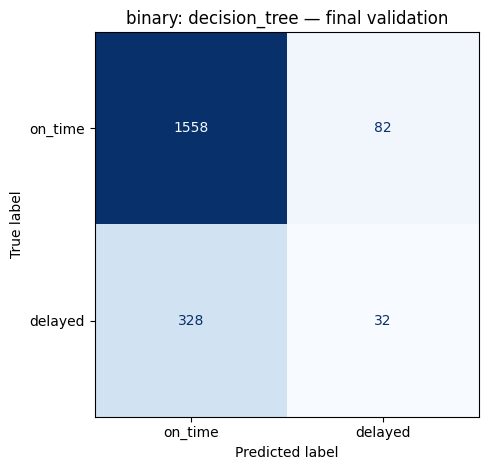

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Validation accuracy:          0.8185
Validation balanced accuracy: 0.5034
Validation macro F1:          0.4608
Final training runtime:       7.1295 seconds
Prediction runtime:           0.2004 seconds


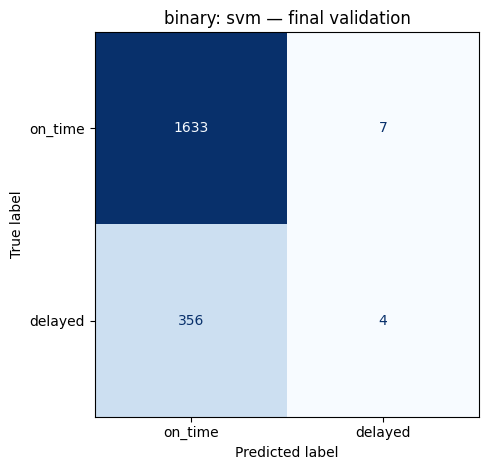

Fitting 5 folds for each of 10 candidates, totalling 50 fits


/Users/emilyiorio/Library/Python/3.9/lib/python/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Validation accuracy:          0.7790
Validation balanced accuracy: 0.5281
Validation macro F1:          0.5269
Final training runtime:       0.0549 seconds
Prediction runtime:           0.2399 seconds


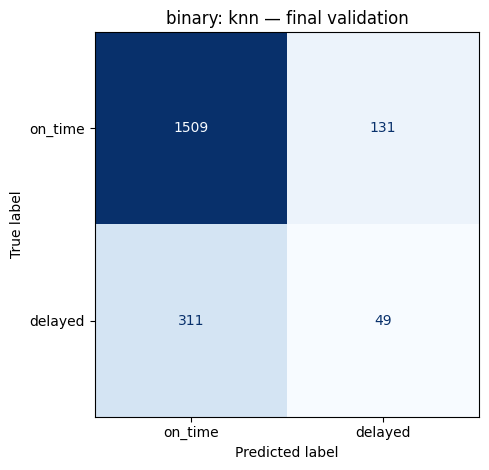

Fitting 5 folds for each of 10 candidates, totalling 50 fits


/Users/emilyiorio/Library/Python/3.9/lib/python/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Validation accuracy:          0.6935
Validation balanced accuracy: 0.5844
Validation macro F1:          0.5643
Final training runtime:       0.1645 seconds
Prediction runtime:           0.0176 seconds


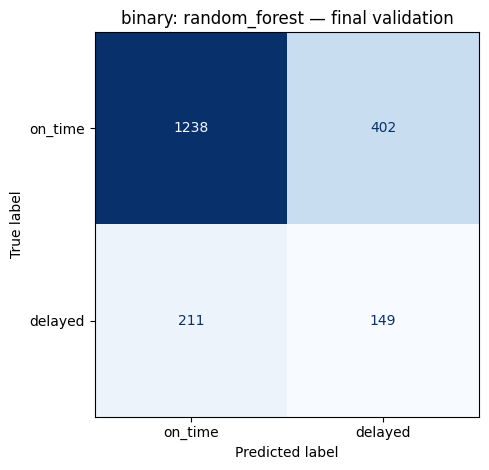

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.7885
Validation balanced accuracy: 0.3460
Validation macro F1:          0.3389
Final training runtime:       0.1545 seconds
Prediction runtime:           0.0039 seconds


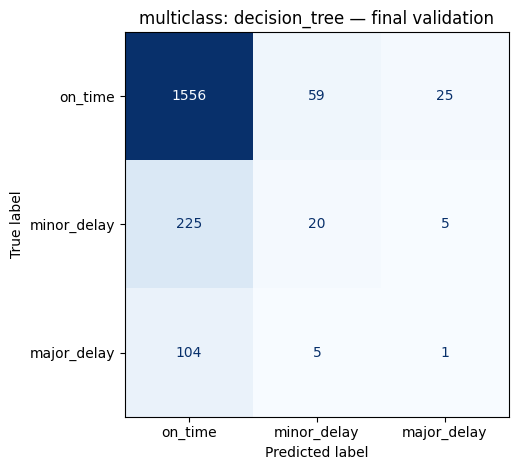

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Validation accuracy:          0.8185
Validation balanced accuracy: 0.3339
Validation macro F1:          0.3027
Final training runtime:       8.1471 seconds
Prediction runtime:           0.2553 seconds


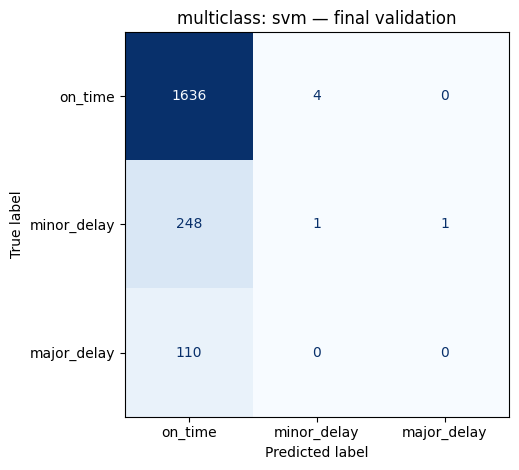

Fitting 5 folds for each of 10 candidates, totalling 50 fits


/Users/emilyiorio/Library/Python/3.9/lib/python/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Validation accuracy:          0.7680
Validation balanced accuracy: 0.3365
Validation macro F1:          0.3291
Final training runtime:       0.0397 seconds
Prediction runtime:           0.2083 seconds


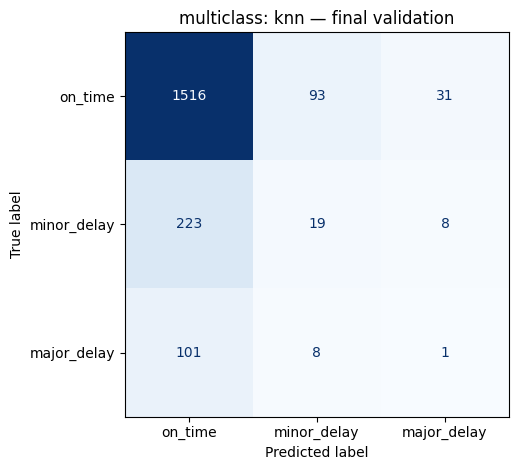

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Validation accuracy:          0.6570
Validation balanced accuracy: 0.3745
Validation macro F1:          0.3635
Final training runtime:       0.1611 seconds
Prediction runtime:           0.0186 seconds


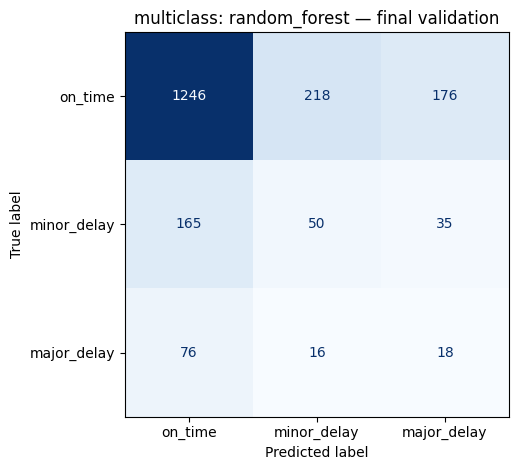

,classification,model,best_parameters,cv_macro_f1,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,training_seconds,prediction_seconds
3,binary,random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.559431,0.6935,0.584383,0.564333,0.164539,0.017558
2,binary,knn,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.521989,0.7790,0.528117,0.526868,0.054916,0.239945
0,binary,decision_tree,{'model__max_depth': 20},0.504156,0.7950,0.519444,0.509371,0.138330,0.003323
1,binary,svm,{'model__kernel': 'poly'},0.453878,0.8185,0.503421,0.460768,7.129516,0.200422
7,multiclass,random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.377649,0.6570,0.374464,0.363464,0.161056,0.018563
4,multiclass,decision_tree,{'model__max_depth': 20},0.342399,0.7885,0.345957,0.338927,0.154539,0.003928
6,multiclass,knn,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.354910,0.7680,0.336494,0.329100,0.039714,0.208327
5,multiclass,svm,{'model__kernel': 'poly'},0.304459,0.8185,0.333854,0.302743,8.147118,0.255333


In [24]:
results = []
best_models = {}
cv_tables = {}

for classification, split in splits.items():
    X_train, y_train, X_validation, y_validation = split

    folds = list(StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train))

    for model in models:
        model_estimator, hyperparameters = model_specs[model]
        pipeline = make_pipeline(model_estimator)

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=hyperparameters,
            scoring="f1_macro",
            cv=folds,
            n_jobs=-1,
            verbose=1,
            refit=False,
        )

        grid_search.fit(X_train, y_train)

        cv_table = pd.DataFrame(grid_search.cv_results_)
        cv_tables[(classification, model)] = cv_table

        mean_test_scores = cv_table[["mean_test_score", "std_test_score"]].copy()

        best_index = mean_test_scores["mean_test_score"].idxmax()
        best_params = grid_search.cv_results_["params"][best_index]

        best_model = make_pipeline(model_estimator).set_params(**best_params)
        
        start_time = perf_counter()
        best_model.fit(X_train, y_train)
        fit_time = perf_counter() - start_time

        start_time = perf_counter()
        predictions = best_model.predict(X_validation)
        prediction_seconds = perf_counter() - start_time

        best_models[(classification, model)] = best_model
        accuracy = accuracy_score(y_validation, predictions)
        balanced_accuracy = balanced_accuracy_score(y_validation, predictions)
        macro_f1 = f1_score(y_validation, predictions, average="macro")

        labels = np.arange(len(class_names[classification]))

        print(f"Validation accuracy:          {accuracy:.4f}")
        print(f"Validation balanced accuracy: {balanced_accuracy:.4f}")
        print(f"Validation macro F1:          {macro_f1:.4f}")
        print(f"Final training runtime:       {fit_time:.4f} seconds")
        print(f"Prediction runtime:           {prediction_seconds:.4f} seconds")

        ConfusionMatrixDisplay.from_predictions(
            y_validation,
            predictions,
            labels=labels,
            display_labels=class_names[classification],
            cmap="Blues",
            colorbar=False,
        )

        plt.title(f"{classification}: {model} — final validation")
        plt.tight_layout()
        plt.show()

        results.append({
            "classification": classification,
            "model": model,
            "best_parameters": str(best_params),
            "cv_macro_f1": mean_test_scores.loc[best_index, "mean_test_score"],
            "validation_accuracy": accuracy,
            "validation_balanced_accuracy": balanced_accuracy,
            "validation_macro_f1": macro_f1,
            "training_seconds": fit_time,
            "prediction_seconds": prediction_seconds,
        })

results_df = pd.DataFrame(results)
display(results_df.sort_values(["classification", "validation_macro_f1"], ascending=[True, False]))
results_df.to_csv(OUTPUT_DIR / "model_fitting_results.csv", index=False)
for (classification, model), cv_table in cv_tables.items():
    cv_table.to_csv(OUTPUT_DIR / f"cv_results_{classification}_{model}.csv", index=False)  

